# 07 — Naive Bayes ile Yangın Noktası Sınıflandırması

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

Naive Bayes, Bayes teoremini "özellikler sınıf verildiğinde birbirinden bağımsızdır"
varsayımıyla uygular. GaussianNB sürümü, her özelliğin her sınıf içinde normal
dağıldığını kabul eder. Bu veride iki varsayım da açıkça çiğnenir: sıcaklık ile yükseklik
birbirine sıkı bağlıdır (yükseldikçe hava soğur); uzaklık değişkenleri sağa çarpıktır,
arazi örtüsü göstergeleri ise yalnızca 0 ya da 1 değerini alır. Yöntem yine de hızlıdır,
olasılık üretir ve güçlü bir referans noktası sunar. Yalnızca sınıflandırma yapar.

## 1. Veri Hazırlığı

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
tb = o.taban_cizgileri(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)

6410 nokta · yangın 3144 · yangın yok 3266


Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']


## 2. Model Eğitimi ve Test Performansı

In [2]:
clf = GaussianNB(priors=[0.5, 0.5])   # düzgün önsel — iki sınıfa eşit başlangıç olasılığı
clf.fit(X_tr, yc_tr)
yp = clf.predict(X_te)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
olasilik = clf.predict_proba(X_te)[:, list(clf.classes_).index(o.POZITIF)]
auc = o.reg_metrikleri(yr_te, olasilik)["AUC"]
print(f"{'ROC-AUC':>14}: {auc:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))
print("Kullanılan sınıf önselleri (düzgün):")
for et, p in zip(clf.classes_, clf.class_prior_):
    print(f"  {et:>10}: {p:.4f}")

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.7395
   BalancedAcc: 0.7411
      F1_macro: 0.7381
   F1_weighted: 0.7378
       ROC-AUC: 0.8282

              precision    recall  f1-score   support

  Yangın Yok      0.797     0.655     0.719       653
      Yangın      0.698     0.827     0.757       629

    accuracy                          0.739      1282
   macro avg      0.748     0.741     0.738      1282
weighted avg      0.748     0.739     0.738      1282

Kullanılan sınıf önselleri (düzgün):
      Yangın: 0.5000
  Yangın Yok: 0.5000


In [3]:
print("Taban çizgileri")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f} ise Yangın, değilse Yangın Yok")

Taban çizgileri
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.7395 |   0.5094 |    0.6934 | +0.0460
     BalancedAcc |  0.7411 |   0.5000 |    0.6982 | +0.0429
        F1_macro |  0.7381 |   0.3375 |    0.6748 | +0.0633
     F1_weighted |  0.7378 |   0.3438 |    0.6733 | +0.0644
Tek kural: Yükseklik ≤ 1258.0 ise Yangın, değilse Yangın Yok


In [4]:
o.karmasiklik_grafigi(yc_te, yp, "Naive Bayes", "nb")

Naive Bayes — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   428    225
      Yangın |   109    520


'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\nb_siniflandirma.png'

## 3. Algoritmaya Özgü Analiz: Sınıf Koşullu Dağılımlar

GaussianNB'nin öğrendiği tek şey, her özellik × sınıf çifti için bir ortalama ve bir
varyanstır. Aşağıdaki eğriler üç özellikte sınıfların ne kadar ayrıştığını gösterir.
Yükseklik ve sıcaklıkta eğriler belirgin biçimde ayrılır; yerleşime uzaklıkta ise
gerçek dağılımın sağa çarpıklığı, Gauss varsayımından ne kadar uzaklaşıldığını gösterir.

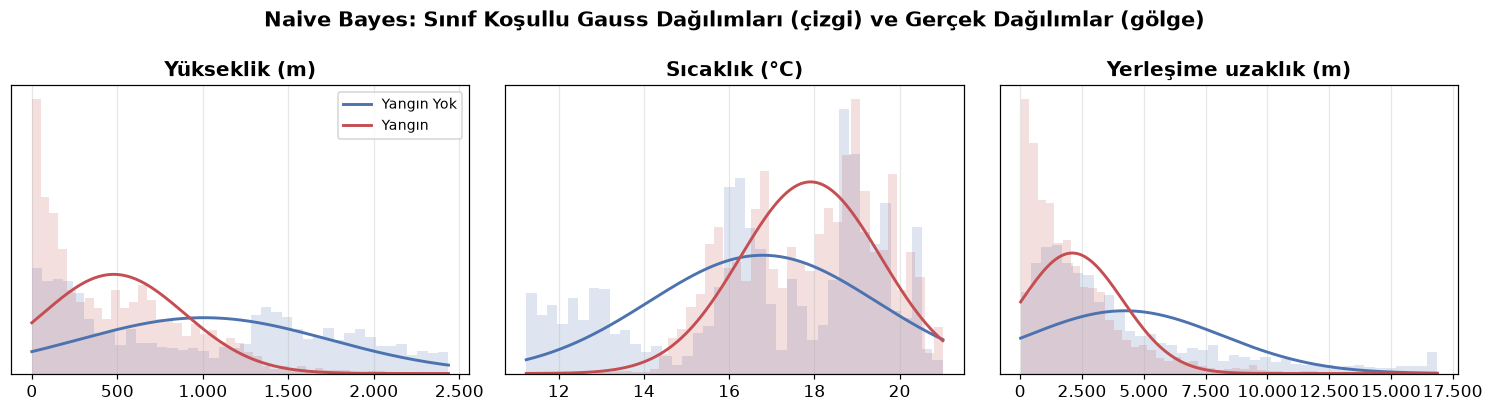

Sınıf ortalamaları (seçili özellikler):
            Yukseklik  Sicaklik  Yerlesim_Uzaklik
Yangın Yok    1005.88     16.79           4230.59
Yangın         478.85     17.91           2107.51

Çarpıklık (eğitim kümesi): {'Yukseklik': 0.77, 'Sicaklik': -0.79, 'Yerlesim_Uzaklik': 1.96}
Yükseklik–sıcaklık korelasyonu: -0.686


In [5]:
GOSTER = ["Yukseklik", "Sicaklik", "Yerlesim_Uzaklik"]
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
renk = dict(zip(o.SINIF_ETIKETLERI, ["#4c72b0", "#c44e52"]))
for ax, oz in zip(axes, GOSTER):
    j = o.OZELLIKLER.index(oz)
    alt = float(X_tr[oz].quantile(0.005))
    ust = float(X_tr[oz].quantile(0.995))
    xs = np.linspace(alt, ust, 300)
    for et in o.SINIF_ETIKETLERI:
        i = list(clf.classes_).index(et)
        mu, var = clf.theta_[i, j], clf.var_[i, j]
        ax.hist(X_tr.loc[yc_tr == et, oz].clip(alt, ust), bins=40, density=True,
                color=renk[et], alpha=0.18)
        ax.plot(xs, stats.norm.pdf(xs, mu, np.sqrt(var)), color=renk[et], lw=1.9, label=et)
    ax.set_title(f"{o.OKUNUR[oz]} ({o.BIRIM[oz]})")
    ax.set_yticks([])
axes[0].legend(fontsize=9)
fig.suptitle("Naive Bayes: Sınıf Koşullu Gauss Dağılımları (çizgi) ve Gerçek Dağılımlar (gölge)",
             fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "nb_gauss.png"), bbox_inches="tight")
plt.show()
ort = pd.DataFrame(clf.theta_, index=clf.classes_, columns=o.OZELLIKLER).reindex(o.SINIF_ETIKETLERI)
print("Sınıf ortalamaları (seçili özellikler):")
print(ort[GOSTER].round(2).to_string())
print()
print("Çarpıklık (eğitim kümesi):", {oz: round(float(X_tr[oz].skew()), 2) for oz in GOSTER})
print("Yükseklik–sıcaklık korelasyonu:", round(float(X_tr["Yukseklik"].corr(X_tr["Sicaklik"])), 3))

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [6]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    c_tahmin = GaussianNB(priors=[0.5, 0.5]).fit(Xa, ysa).predict(Xb)
    cv_r2.append(float("nan"))  # bu algoritma regresyon yapmaz
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +nan · F1-makro 0.7186
  kat 2: eğitim  4170 · sınama   958 · R² +nan · F1-makro 0.5478
  kat 3: eğitim  4114 · sınama  1014 · R² +nan · F1-makro 0.7375
  kat 4: eğitim  4055 · sınama  1073 · R² +nan · F1-makro 0.7297
  kat 5: eğitim  4150 · sınama   978 · R² +nan · F1-makro 0.7185
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +nan ± nan
  F1-makro: 0.6904 ± 0.0717


C:\Users\BALTRON\AppData\Local\Temp\ipykernel_20660\3928516698.py:14: RuntimeWarning: Mean of empty slice
  print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\.venv\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


In [7]:
o.sonuc_kaydet("naive_bayes", None, cls,
               ek={"cv": cv_ozet, "tahmin": [str(v) for v in yp], "auc": auc,
                   "sinif_ortalamalari": ort[GOSTER].round(4).to_dict(orient="index"),
                   "carpiklik": {oz: float(X_tr[oz].skew()) for oz in GOSTER},
                   "yukseklik_sicaklik_r": float(X_tr["Yukseklik"].corr(X_tr["Sicaklik"]))})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\naive_bayes.json


{'algoritma': 'naive_bayes',
 'regresyon': None,
 'siniflandirma': {'Accuracy': 0.7394695787831513,
  'BalancedAcc': 0.7410727545850508,
  'F1_macro': 0.7381209252259856,
  'F1_weighted': 0.7377691025588989},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [None, None, None, None, None],
   'F1_macro': [0.7185994624185906,
    0.5477972027972028,
    0.7374854189737912,
    0.7297013224369532,
    0.7184505314148223],
   'R2_ort': None,
   'R2_std': None,
   'F1_ort': 0.690406787608272,
   'F1_std': 0.07166481725126525},
  'tahmin': ['Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Yangın',
   'Y